In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [4]:
#dataset
layers = tf.keras.layers
keras.utils.set_random_seed(42)
tr = pd.read_csv("sign_mnist_train.csv")
te = pd.read_csv("sign_mnist_test.csv")

(26337, 28, 28, 1) (7172, 28, 28, 1) 332 7172


In [5]:
#split
to_img = lambda d: d.drop(columns="label").values.astype("float32").reshape(-1,28,28,1) / 255.0
Xtrall, labtr = to_img(tr), tr["label"].values
Xtes, labte = to_img(te), te["label"].values
Xtrn = Xtrall[labtr != 24]
yte = (labte == 24).astype(int)
print(Xtrn.shape, Xtes.shape, yte.sum(),len(yte))

(26337, 28, 28, 1) (7172, 28, 28, 1) 332 7172


In [9]:
#layers
inp = keras.Input(shape=(28,28,1))
x = layers.Conv2D(32,3,strides=2,padding="same",activation="relu")(inp)
x = layers.Conv2D(64,3,strides=2,padding="same",activation="relu")(x)
x = layers.Flatten()(x)
z = layers.Dense(32,activation="relu")(x)
x = layers.Dense(7*7*64,activation="relu")(z)
x = layers.Reshape((7,7,64))(x)
x = layers.Conv2DTranspose(64,3,strides=2,padding="same",activation="relu")(x)
x = layers.Conv2DTranspose(32,3,strides=2,padding="same",activation="relu")(x)
out = layers.Conv2D(1,3,padding="same",activation="sigmoid")(x)
ae = keras.Model(inp,out)
ae.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 28, 28, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 14, 14, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 7, 7, 64)            │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │         100,384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3136)                │         103,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)   │ (None, 14, 14, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose) │ (None, 28, 28, 32)          │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 1)           │             289 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 278,369 (1.06 MB)

 Trainable params: 278,369 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
#compile
ae.compile(optimizer="adam",loss="mse",metrics=["mae"])
hist = ae.fit(Xtrn,Xtrn,epochs=40,validation_split=0.1,batch_size=128)

Epoch 1/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0331 - mae: 0.1424 - val_loss: 0.0162 - val_mae: 0.0887
Epoch 2/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0134 - mae: 0.0804 - val_loss: 0.0083 - val_mae: 0.0627
Epoch 3/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0079 - mae: 0.0611 - val_loss: 0.0072 - val_mae: 0.0583
Epoch 4/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0068 - mae: 0.0566 - val_loss: 0.0064 - val_mae: 0.0541
Epoch 5/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0063 - mae: 0.0538 - val_loss: 0.0061 - val_mae: 0.0528
Epoch 6/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0059 - mae: 0.0521 - val_loss: 0.0058 - val_mae: 0.0508
Epoch 7/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0057 - mae: 0.0507 - val_loss: 0.0055 - val_mae: 0.0494
Epoch 8/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0054 - mae: 0.0492 - val_loss: 0.0053 - val_mae: 0.0485
Epoch 9/40
186/186 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/

In [19]:
#reconstruction error
err_train = np.mean((Xtrn - ae.predict(Xtrn))**2,axis=(1,2,3))
err_test = np.mean((Xtes - ae.predict(Xtes))**2,axis=(1,2,3))
threshold = np.percentile(err_train,95)
pred = (err_test > threshold).astype(int)
print(threshold, pred.sum(),len(pred))

824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
0.005657125357538453 3004 7172


In [20]:
#evaluate
print(classification_report(yte,pred,target_names=["normal","anomaly"],digits=3))
print(confusion_matrix(yte,pred))
print(round(roc_auc_score(yte,err_test),4))

              precision    recall  f1-score   support

      normal      0.992     0.605     0.751      6840
     anomaly      0.100     0.904     0.180       332

    accuracy                          0.619      7172
   macro avg      0.546     0.754     0.466      7172
weighted avg      0.951     0.619     0.725      7172

[[4136 2704]
 [  32  300]]
0.8254


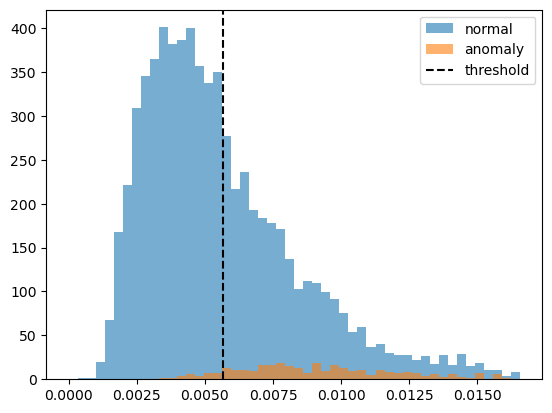

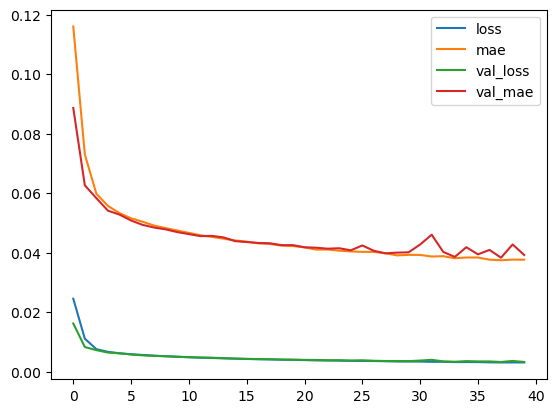

In [21]:
#plot
for k in (0,1):
    plt.hist(err_test[yte==k],50,range=(0,np.percentile(err_test,99)),alpha=0.6,label=["normal","anomaly"][k])
plt.axvline(threshold,color="k",ls="--",label="threshold")
plt.legend()
pd.DataFrame(hist.history).plot();
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


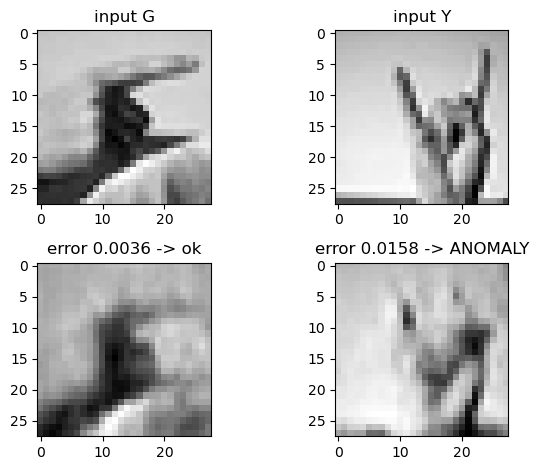

In [22]:
#one example
i = np.where(yte == 0)[0][0]                       # first normal letter
j = np.where((yte == 1) & (pred == 1))[0][0]       # first Y the model caught
for n, k in enumerate((i, j)):
    plt.subplot(2, 2, n+1); plt.imshow(Xtes[k,:,:,0], cmap="gray"); plt.title(f"input {chr(65+labte[k])}")
    plt.subplot(2, 2, n+3); plt.imshow(ae.predict(Xtes[k:k+1])[0,:,:,0], cmap="gray"); plt.title(f"error {err_test[k]:.4f} -> {'ANOMALY' if pred[k] else 'ok'}")
plt.tight_layout(); plt.show()